# Monte Carlo Greeks: pathwise, likelihood ratio, bump-and-reprice

Checks on `pricing.mc_greeks`:

1. **Call delta and vega** from the three estimators against the analytical Greeks: bias and standard error at the same number of paths.
2. **Bump size** in bump-and-reprice, with common random numbers (CRN) and with independent draws: the noise/bias trade-off.
3. **Digital payoff**: why pathwise fails, and what likelihood ratio and bumping do instead.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from pricing.greeks import analytical_greeks
from pricing.mc_greeks import mc_delta, mc_vega

In [2]:
# Market parameters (same as previous notebooks, for comparability)
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
q = 0.02
n_paths = 200_000

exact = analytical_greeks(S0, K, T, r, sigma, "call", q)
print(f"Analytical call delta = {exact.delta:.5f}, vega = {exact.vega:.5f}")

Analytical call delta = 0.58685, vega = 37.90116


## 1. Delta and vega of a call

The three ideas, for $V=e^{-rT}\mathbb{E}[f(S_T)]$ with $S_T=S\exp((r-q-\sigma^2/2)T+\sigma\sqrt{T}Z)$:

- **Pathwise**: $\partial V/\partial S=e^{-rT}\mathbb{E}[f'(S_T)\,S_T/S]$, differentiating the payoff.
- **Likelihood ratio**: $\partial V/\partial S=e^{-rT}\mathbb{E}[f(S_T)\,Z/(S\sigma\sqrt{T})]$, differentiating the density, so $f$ never gets differentiated.
- **Bump**: $(V(S+h)-V(S-h))/2h$ with the same $Z$ in both (CRN) or different ones.

In [3]:
rows = []
for label, kwargs in [("pathwise", dict(method="pathwise")),
                      ("likelihood ratio", dict(method="likelihood_ratio")),
                      ("bump 1%, CRN", dict(method="bump", bump=0.01, common_random_numbers=True)),
                      ("bump 1%, independent", dict(method="bump", bump=0.01, common_random_numbers=False))]:
    est = mc_delta(S0, K, T, r, sigma, "call", q, n_paths=n_paths, seed=11, **kwargs)
    rows.append({"estimator": label, "delta": est.value, "SE": est.std_error, "error vs analytical": est.value - exact.delta,
                 "error / SE": (est.value - exact.delta) / est.std_error})
vega = mc_vega(S0, K, T, r, sigma, "call", q, n_paths=n_paths, seed=11)
print(f"Pathwise vega: {vega.value:.4f} +- {vega.std_error:.4f}   analytical: {exact.vega:.4f}")
pd.DataFrame(rows).round(5)

Pathwise vega: 37.6930 +- 0.1636   analytical: 37.9012


,estimator,delta,SE,error vs analytical,error / SE
0,pathwise,0.58431,0.00128,-0.00254,-1.98292
1,likelihood ratio,0.58317,0.00309,-0.00368,-1.19199
2,"bump 1%, CRN",0.58431,0.00127,-0.00255,-2.00326
3,"bump 1%, independent",0.55822,0.02189,-0.02864,-1.30805


**Reading the table**

- Pathwise and bump-with-CRN give the same delta to 5 digits (0.58431) and the same SE (0.0013): with a small bump and the same draws, the CRN difference quotient is the pathwise estimator. They also share the same sampling error, which here happens to be 2 SE below the analytical value (0.58685); that is one seed, not a bias.
- Likelihood ratio has an SE of 0.0031, 2.4 times the pathwise one, as expected from not using the payoff derivative.
- Bump with independent draws has an SE of 0.0219, 17 times the CRN one, and its estimate (0.558) is off by 0.029. With 200k paths it is still useful only to one digit.
- The pathwise vega is $37.69\pm0.16$ against the analytical 37.90, within 1.3 SE.

## 2. The bump size

A small bump has little bias but amplifies noise: the price difference is divided by $2h$. With independent draws the noise of each price does not cancel, so the SE grows like $1/h$. With CRN the two prices are strongly correlated and, for a call, whose payoff is continuous, the difference quotient is bounded by the slope of the payoff, so its noise should not blow up as $h$ shrinks; the price of a large $h$ is a finite-difference bias instead. The table shows the SE for several relative bumps; the sampling is repeated for 20 seeds so that the bias (mean over seeds minus analytical) and the spread (std over seeds) can be read separately.

In [4]:
bumps = [1e-4, 1e-3, 1e-2, 1e-1]
rows = []
for crn in (True, False):
    for b in bumps:
        vals = [mc_delta(S0, K, T, r, sigma, "call", q, method="bump", bump=b, common_random_numbers=crn, n_paths=50_000, seed=200 + s).value for s in range(20)]
        rows.append({"CRN": crn, "bump (relative)": b, "mean error": np.mean(vals) - exact.delta, "std over seeds": np.std(vals, ddof=1)})
df_bump = pd.DataFrame(rows)
df_bump.round(5)

,CRN,bump (relative),mean error,std over seeds
0,True,0.0001,-0.00005,0.00231
1,True,0.0010,-0.00005,0.00227
2,True,0.0100,-0.00016,0.00224
3,True,0.1000,-0.00686,0.00214
4,False,0.0001,1.54448,3.87785
5,False,0.0010,0.15431,0.38788
6,False,0.0100,0.01512,0.03883
7,False,0.1000,-0.00543,0.00393


- **Independent draws**: the std over seeds goes 3.88, 0.388, 0.0388, 0.0039 as the bump goes from $10^{-4}$ to $10^{-1}$: exactly proportional to $1/h$. The mean errors at the small bumps (1.54 and 0.15) are about 1.8 standard errors from zero given those spreads (standard error of the mean over 20 seeds: 0.87 and 0.087); at the larger bumps they shrink with the spread, so it reads as noise rather than bias.
- **CRN**: the std is flat at about 0.0022 over three decades of $h$, so for a call there is nothing to gain from using a big bump. What does grow with $h$ is the bias, from about $-0.00005$ at $h=0.01\%$ and $0.1\%$ to $-0.0069$ at 10%, which is the curvature (gamma) error of a central difference. The rule that comes out: with CRN take $h$ small (here 0.1% to 1%); without CRN the method is not usable at small $h$.

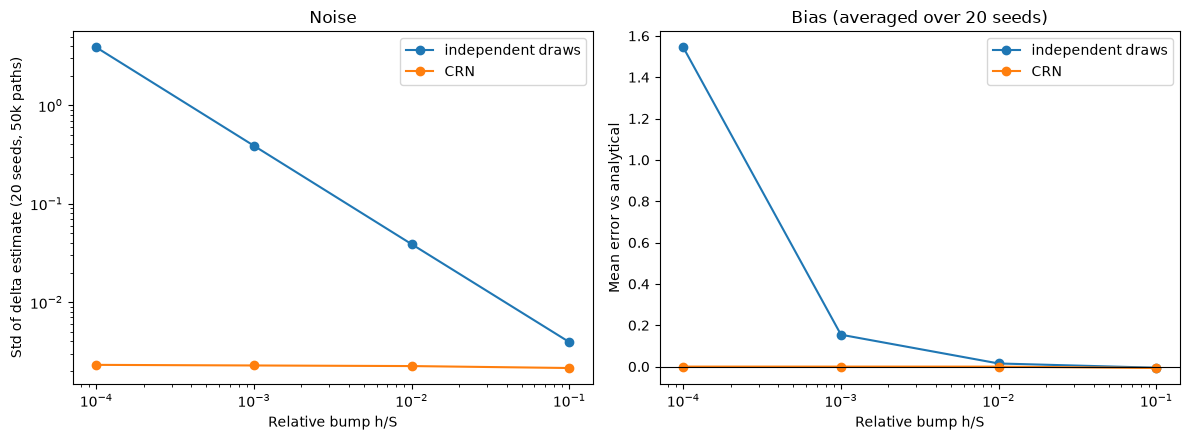

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for crn, g in df_bump.groupby("CRN"):
    axes[0].loglog(g["bump (relative)"], g["std over seeds"], "o-", label="CRN" if crn else "independent draws")
    axes[1].semilogx(g["bump (relative)"], g["mean error"], "o-", label="CRN" if crn else "independent draws")
axes[0].set_xlabel("Relative bump h/S"); axes[0].set_ylabel("Std of delta estimate (20 seeds, 50k paths)"); axes[0].set_title("Noise"); axes[0].legend()
axes[1].axhline(0, color="k", linewidth=0.8)
axes[1].set_xlabel("Relative bump h/S"); axes[1].set_ylabel("Mean error vs analytical"); axes[1].set_title("Bias (averaged over 20 seeds)"); axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Digital call

The payoff $\mathbf{1}\{S_T>K\}$ is flat except for a jump at $K$. Its derivative is zero everywhere it exists, so the pathwise estimator is identically zero (and wrong): the whole sensitivity sits in the probability of crossing the strike, which the pathwise approach ignores. `mc_delta` refuses this combination.

In [6]:
try:
    mc_delta(S0, K, T, r, sigma, "digital_call", q, method="pathwise")
except ValueError as e:
    print("ValueError:", e)

d2 = (np.log(S0 / K) + (r - q - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
digital_delta = np.exp(-r * T) * norm.pdf(d2) / (S0 * sigma * np.sqrt(T))
print(f"\nAnalytical digital delta = {digital_delta:.6f}")

rows = []
for label, kwargs in [("likelihood ratio", dict(method="likelihood_ratio")),
                      ("bump 1%, CRN", dict(method="bump", bump=0.01, common_random_numbers=True)),
                      ("bump 0.1%, CRN", dict(method="bump", bump=0.001, common_random_numbers=True)),
                      ("bump 1%, independent", dict(method="bump", bump=0.01, common_random_numbers=False))]:
    est = mc_delta(S0, K, T, r, sigma, "digital_call", q, n_paths=n_paths, seed=11, **kwargs)
    rows.append({"estimator": label, "delta": est.value, "SE": est.std_error, "error / SE": (est.value - digital_delta) / est.std_error})
pd.DataFrame(rows).round(6)

ValueError: Pathwise delta is invalid for a digital payoff (zero a.e. derivative).

Analytical digital delta = 0.018951


,estimator,delta,SE,error / SE
0,likelihood ratio,0.018858,0.000062,-1.494688
1,"bump 1%, CRN",0.019198,0.000209,1.182959
2,"bump 0.1%, CRN",0.019381,0.000678,0.635737
3,"bump 1%, independent",0.017388,0.000752,-2.077157


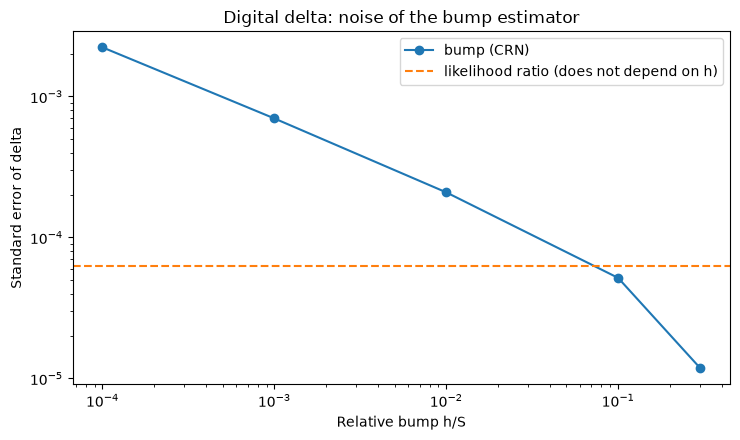

,bump,bump SE,bump error
0,0.0001,0.002230,0.001976
1,0.0010,0.000699,0.001667
2,0.0100,0.000209,0.000181
3,0.1000,0.000052,-0.000729
4,0.3000,0.000012,-0.005135


In [7]:
# Standard error of the digital delta vs bump size (CRN) compared to the likelihood-ratio SE, same number of paths.
lr = mc_delta(S0, K, T, r, sigma, "digital_call", q, method="likelihood_ratio", n_paths=n_paths, seed=5)
rows = []
for b in [1e-4, 1e-3, 1e-2, 1e-1, 3e-1]:
    est = mc_delta(S0, K, T, r, sigma, "digital_call", q, method="bump", bump=b, common_random_numbers=True, n_paths=n_paths, seed=5)
    rows.append({"bump": b, "bump SE": est.std_error, "bump error": est.value - digital_delta})
df_dig = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(df_dig["bump"], df_dig["bump SE"], "o-", label="bump (CRN)")
ax.axhline(lr.std_error, color="C1", linestyle="--", label="likelihood ratio (does not depend on h)")
ax.set_xlabel("Relative bump h/S"); ax.set_ylabel("Standard error of delta")
ax.set_title("Digital delta: noise of the bump estimator")
ax.legend()
fig.tight_layout()
plt.show()
df_dig.round(6)

**What the digital case shows**

- Pathwise is rejected, as it should be: the derivative of the payoff is zero almost everywhere, so the estimator would return 0 against a true delta of 0.0190.
- Likelihood ratio (0.01886, SE $6.2\times10^{-5}$) and the 1% CRN bump (0.01920, SE $2.1\times10^{-4}$) both agree with the analytical value (within 1.5 SE). The LR estimator has an SE 3.4 times smaller than the 1% bump. This is the opposite of the call case: here the LR does *better*.
- The CRN bump SE grows as the bump shrinks, about 3.2 times per decade (2.2e-3, 7.0e-4, 2.1e-4, 5.2e-5 for 0.01%, 0.1%, 1%, 10%), i.e. like $h^{-1/2}$: only the paths that land between $K$ and $K\pm h$ contribute, a fraction proportional to $h$ of the sample, each with a large weight $1/h$. The bias grows with $h$ in the opposite direction ($-7\times10^{-4}$ at 10%, 14 SE; $-5\times10^{-3}$ at 30%). The best bump here is around 1%, where the error is about 1 SE.
- Independent draws with a 1% bump (SE $7.5\times10^{-4}$) are still 12 times noisier than LR.

So the choice depends on the payoff: smooth payoff, use pathwise (lowest variance); discontinuous payoff, use likelihood ratio, or a smoothed payoff, or a bump that is neither too small nor too large. For path-dependent payoffs the likelihood ratio becomes a sum over the time steps and its variance grows with the number of dates (not tested here).